In [1]:
%store -r combined_df
combined_df


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
644,MS,F,19,R,GT3,T,2,3,services,other,...,5,4,2,1,2,5,4,10,11,10
645,MS,F,18,U,LE3,T,3,1,teacher,services,...,4,3,4,1,1,1,4,15,15,16
646,MS,F,18,U,GT3,T,1,1,other,other,...,1,1,1,1,1,5,6,11,12,9
647,MS,M,17,U,LE3,T,3,1,services,services,...,2,4,5,3,4,2,6,10,10,10


In [2]:
df = combined_df.reset_index(drop=True)


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      649 non-null    object
 1   sex         649 non-null    object
 2   age         649 non-null    int64 
 3   address     649 non-null    object
 4   famsize     649 non-null    object
 5   Pstatus     649 non-null    object
 6   Medu        649 non-null    int64 
 7   Fedu        649 non-null    int64 
 8   Mjob        649 non-null    object
 9   Fjob        649 non-null    object
 10  reason      649 non-null    object
 11  guardian    649 non-null    object
 12  traveltime  649 non-null    int64 
 13  studytime   649 non-null    int64 
 14  failures    649 non-null    int64 
 15  schoolsup   649 non-null    object
 16  famsup      649 non-null    object
 17  paid        649 non-null    object
 18  activities  649 non-null    object
 19  nursery     649 non-null    object
 20  higher    

In [4]:
print(df.isna().sum())

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64


In [5]:
df.columns.tolist()

['school',
 'sex',
 'age',
 'address',
 'famsize',
 'Pstatus',
 'Medu',
 'Fedu',
 'Mjob',
 'Fjob',
 'reason',
 'guardian',
 'traveltime',
 'studytime',
 'failures',
 'schoolsup',
 'famsup',
 'paid',
 'activities',
 'nursery',
 'higher',
 'internet',
 'romantic',
 'famrel',
 'freetime',
 'goout',
 'Dalc',
 'Walc',
 'health',
 'absences',
 'G1',
 'G2',
 'G3']

There are a lot of features. which ones are useful for the target variables? 

One way to check which ones are most important, Mutual informations is good for feature selection when we have mixed data types and when we have no idea about the type of linearity. 

In [6]:
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance
import pandas as pd
from sklearn.feature_selection import mutual_info_regression
from sklearn.preprocessing import OrdinalEncoder

In [7]:
df = df.drop(columns=["G1", "G2"])      

In [8]:
X = df.drop(columns="G3")
y = df["G3"]

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)

In [10]:

X_train_encoded = X_train.copy()
cat_cols = X_train_encoded.select_dtypes(include=['object', 'category']).columns

encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
X_train_encoded[cat_cols] = encoder.fit_transform(X_train_encoded[cat_cols])

mi_scores = mutual_info_regression(X_train_encoded, y_train, random_state=0)
mi_scores = pd.Series(mi_scores, index=X_train.columns).sort_values(ascending=False)

print("Mutual Information Scores (Train Set):")
print(mi_scores)

Mutual Information Scores (Train Set):
failures      0.105721
absences      0.103178
Medu          0.097801
higher        0.080110
schoolsup     0.079519
freetime      0.055699
studytime     0.048492
Walc          0.045065
age           0.044401
Dalc          0.043131
traveltime    0.041161
Fjob          0.039192
Fedu          0.027682
school        0.021594
famsup        0.021175
internet      0.019736
goout         0.016936
Mjob          0.016313
health        0.010942
reason        0.001353
romantic      0.000000
famrel        0.000000
Pstatus       0.000000
nursery       0.000000
activities    0.000000
famsize       0.000000
sex           0.000000
address       0.000000
guardian      0.000000
paid          0.000000
dtype: float64


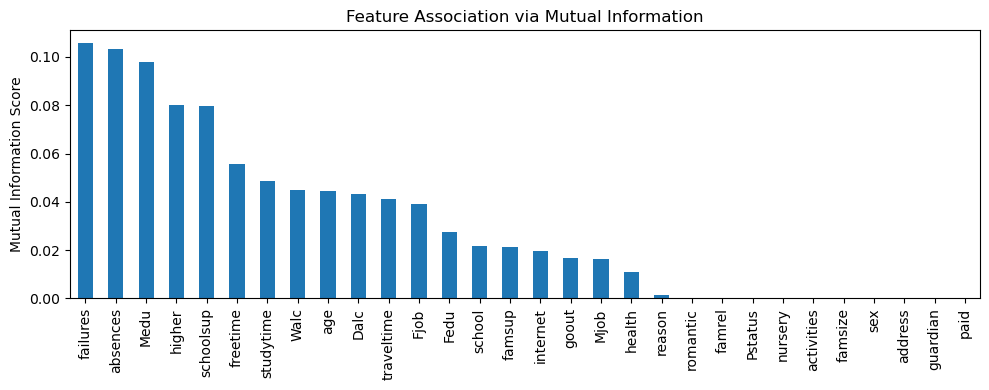

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
mi_scores.plot(kind='bar')
plt.ylabel('Mutual Information Score')
plt.title('Feature Association via Mutual Information')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [12]:
# Set a threshold 
selected_features = mi_scores[mi_scores > 0.01].index.tolist()

print(selected_features)

['failures', 'absences', 'Medu', 'higher', 'schoolsup', 'freetime', 'studytime', 'Walc', 'age', 'Dalc', 'traveltime', 'Fjob', 'Fedu', 'school', 'famsup', 'internet', 'goout', 'Mjob', 'health']
